## 6.2.3 KNN综合实践

&emsp;&emsp;**例5-2-1** 一个随机生成的数据集进行KNN算法的应用示例。

#### （1）导入库
<br>
&emsp;&emsp;sklearn.datasets用于生成样本数据，matplotlib用于可视化图表，sklearn.neighbors用于分类。
<br>
&emsp;&emsp;语句plt.rcParams\['axes.unicode_minus']=False，设置负号不使用Unicode编码。

In [1]:
# 修复Windows GBK编码问题
import builtins

if not getattr(builtins.open, "_is_utf8_patched", False):
    _orig_open = builtins.open

    def _utf8_open(file, mode="r", *args, encoding=None, **kwargs):
        if "b" not in mode and encoding is None:
            encoding = "utf-8"
        return _orig_open(file, mode, *args, encoding=encoding, **kwargs)

    _utf8_open._is_utf8_patched = True  # type: ignore
    builtins.open = _utf8_open

In [2]:
# 开启Intel计算加速
from sklearnex import patch_sklearn

patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


In [3]:
# （1）导入库
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier

plt.rcParams["axes.unicode_minus"] = False

#### （2）生成样本数据并展示
<br>
&emsp;&emsp;语句X,y=make_blobs(n_samples=100,random_state=0,cluster_std=0.6,centers=3,n_features=2)，利用scikit-learn的make_blobs函数生成数量为100个，固定随机数种子为0，标准差为0.6的样本数据集，并将生成的样本返回给X变量，标签返回给y变量。
<br>
&emsp;&emsp;make_blobs函数原型如下：
<br>

&emsp;&emsp;**make_blobs(n_samples=100,random_state=None,cluster_std=0.6,centers=3,n_features=2, …)。**

- n_samples指定样本数量；
- random_state指定随机生成器的种子，保证程序每次运行的训练集和测试集相同；
- cluster_std：指定数据集的标准差；
- centers指定样本集的中心数量；
- n_features指定样本特征数量；

&emsp;&emsp;语句plt.figure(figsize=(16,10),dpi=144)，创建画布，设置图形的大小为16\*10英寸，设置图形每英寸的点数为144个。
<br>
&emsp;&emsp;语句plt.scatter(X\[:,0],X\[:,1],c=y,s=100)，以X数据集的第0列和第1列数据作为两个维度，绘制散点图，设置数据点颜色根据数据标签确定，标记大小为100。

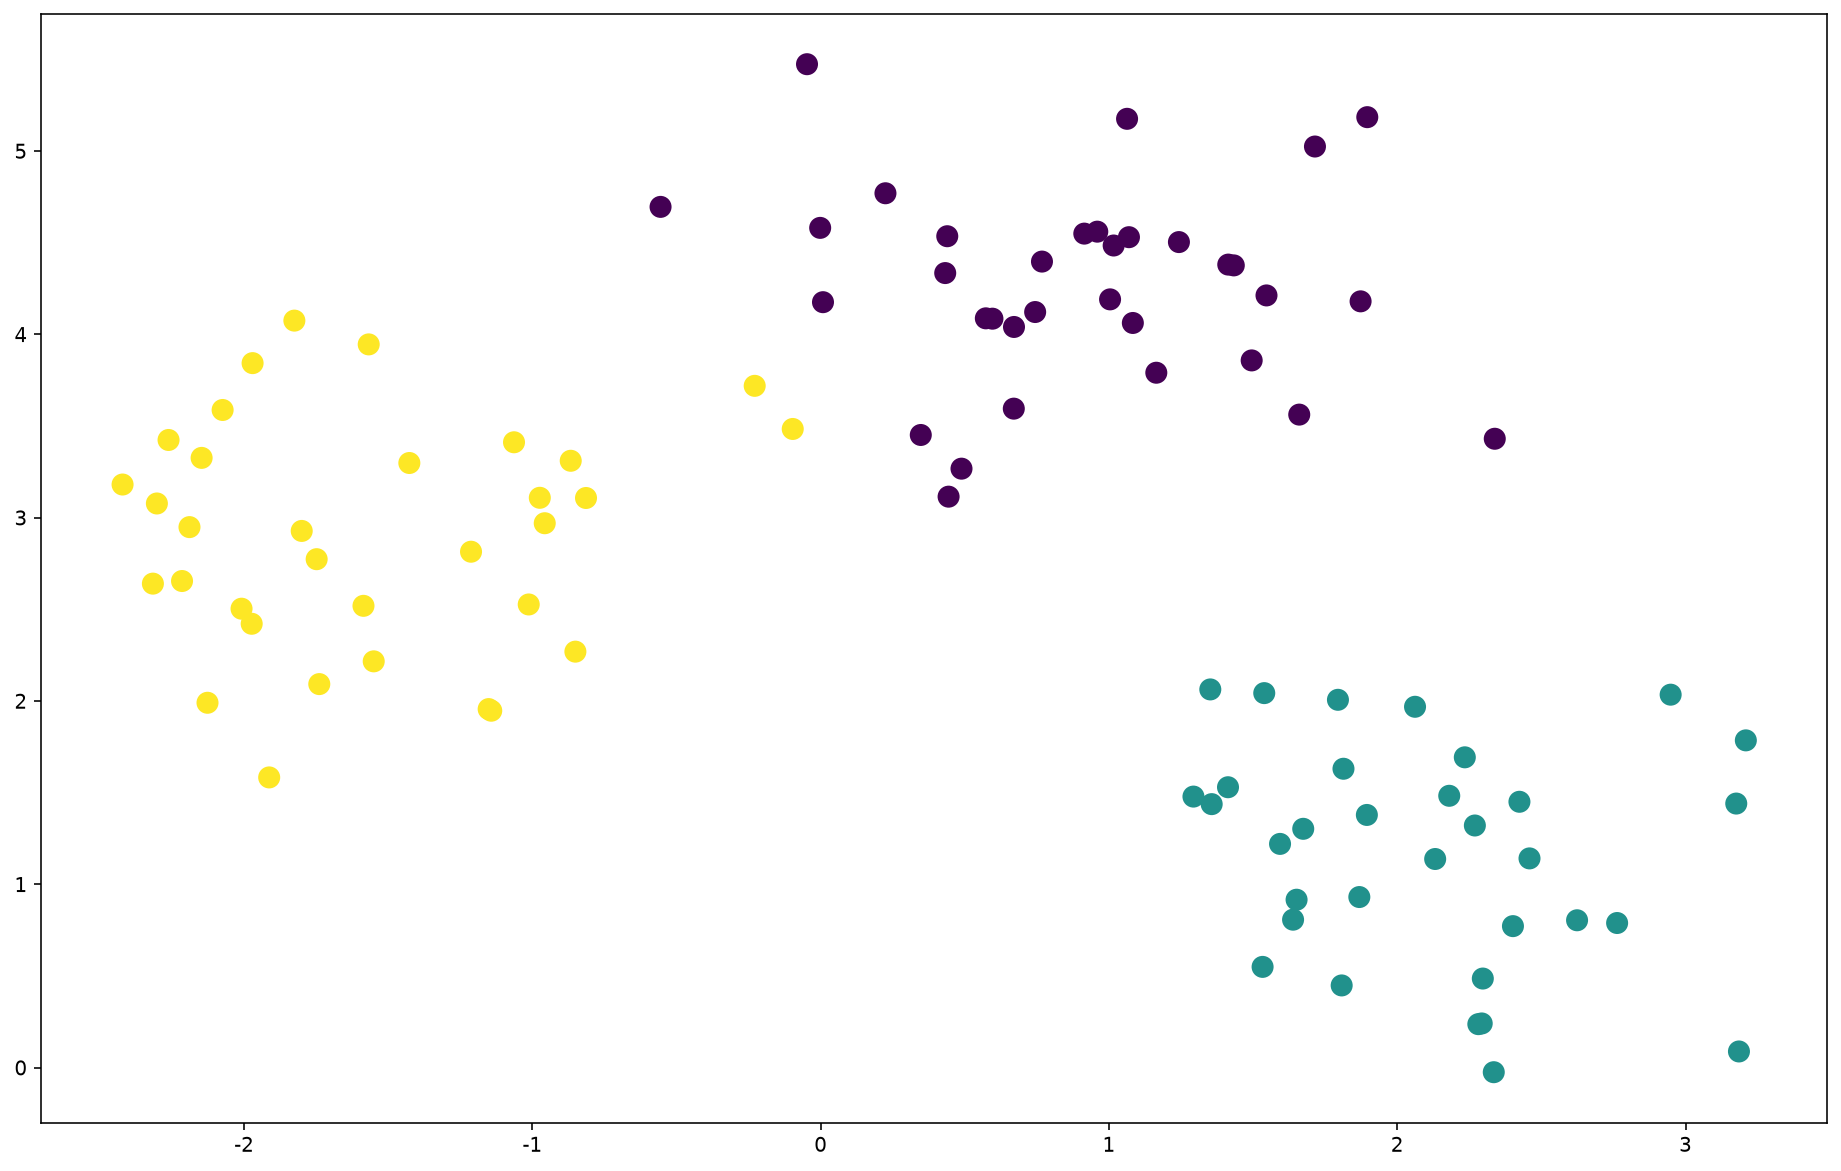

In [4]:
# （2）利用scikit-learn的make_blobs函数生成100个样本点数据，并利用散点图显示
X, y = make_blobs( # type: ignore
    n_samples=100, random_state=0, cluster_std=0.6, centers=3, n_features=2
)
plt.figure(figsize=(16, 10), dpi=144)
plt.scatter(X[:, 0], X[:, 1], c=y, s=100)

#### （3）分类拟合
<br>
&emsp;&emsp;调用scikit-learn中的KneighborsClassifier分类算法对样本数据点构建分类模型。其中最邻点数量选择10，并使用fit()函数拟合模型。

In [5]:
# （3）调用scikit-learn中的KneighborsClassifier分类算法对样本数据点构建分类模型。
k = 10
clf = KNeighborsClassifier(n_neighbors=k)
clf.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[0,1,2]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


#### （4）预测类别
<br>
&emsp;&emsp;对未知类别的样本数据点\[0,2]调用predict函数预测其类别并赋值给y_sample，输出拟合模型对未知数据点\[0,2]的预测结果是：
<br>
&emsp;&emsp;[2]
<br>
&emsp;&emsp;语句y_sample=clf.predict(X_sample)调用predict函数预测样本数据点\[0,2]的类别。
<br>
&emsp;&emsp;语句neighbors=clf.kneighbors(X_sample, return_distance=False)，返回样本数据点的相邻点的索引值的集合，不返回距离。

In [6]:
# （4）对未知类别的样本数据点[0,2]调用predict函数预测其类别。
X_sample = np.array([[0, 2]])
y_sample = clf.predict(X_sample)
neighbors = clf.kneighbors(X_sample, return_distance=False)
print(y_sample)

[2]


#### （5）展示10个最邻近点直线显示图
<br>
&emsp;&emsp;为了更直观显示样本点数据的类型，将10个最邻近点与样本数据点\[0,2]用直线连接起来，从图5-2-4很直观地可以看出样本数据点的类别。
<br>
&emsp;&emsp;语句plt.scatter(X_sample\[:,0],X_sample\[:,1],marker="x",s=100)，画出样本点，参数marker="x"表示样本数据点用符号‘x’表示。
<br>
&emsp;&emsp;语句for i in neighbors\[0]依次遍历10个最邻近点，执行plt.plot(\[X\[i]\[0],X_sample\[0]\[0]],…)语句，画出从样本数据点到每个最邻近点的连线，使用黑色破折线连接数据点和最近邻点，线宽为0.6。

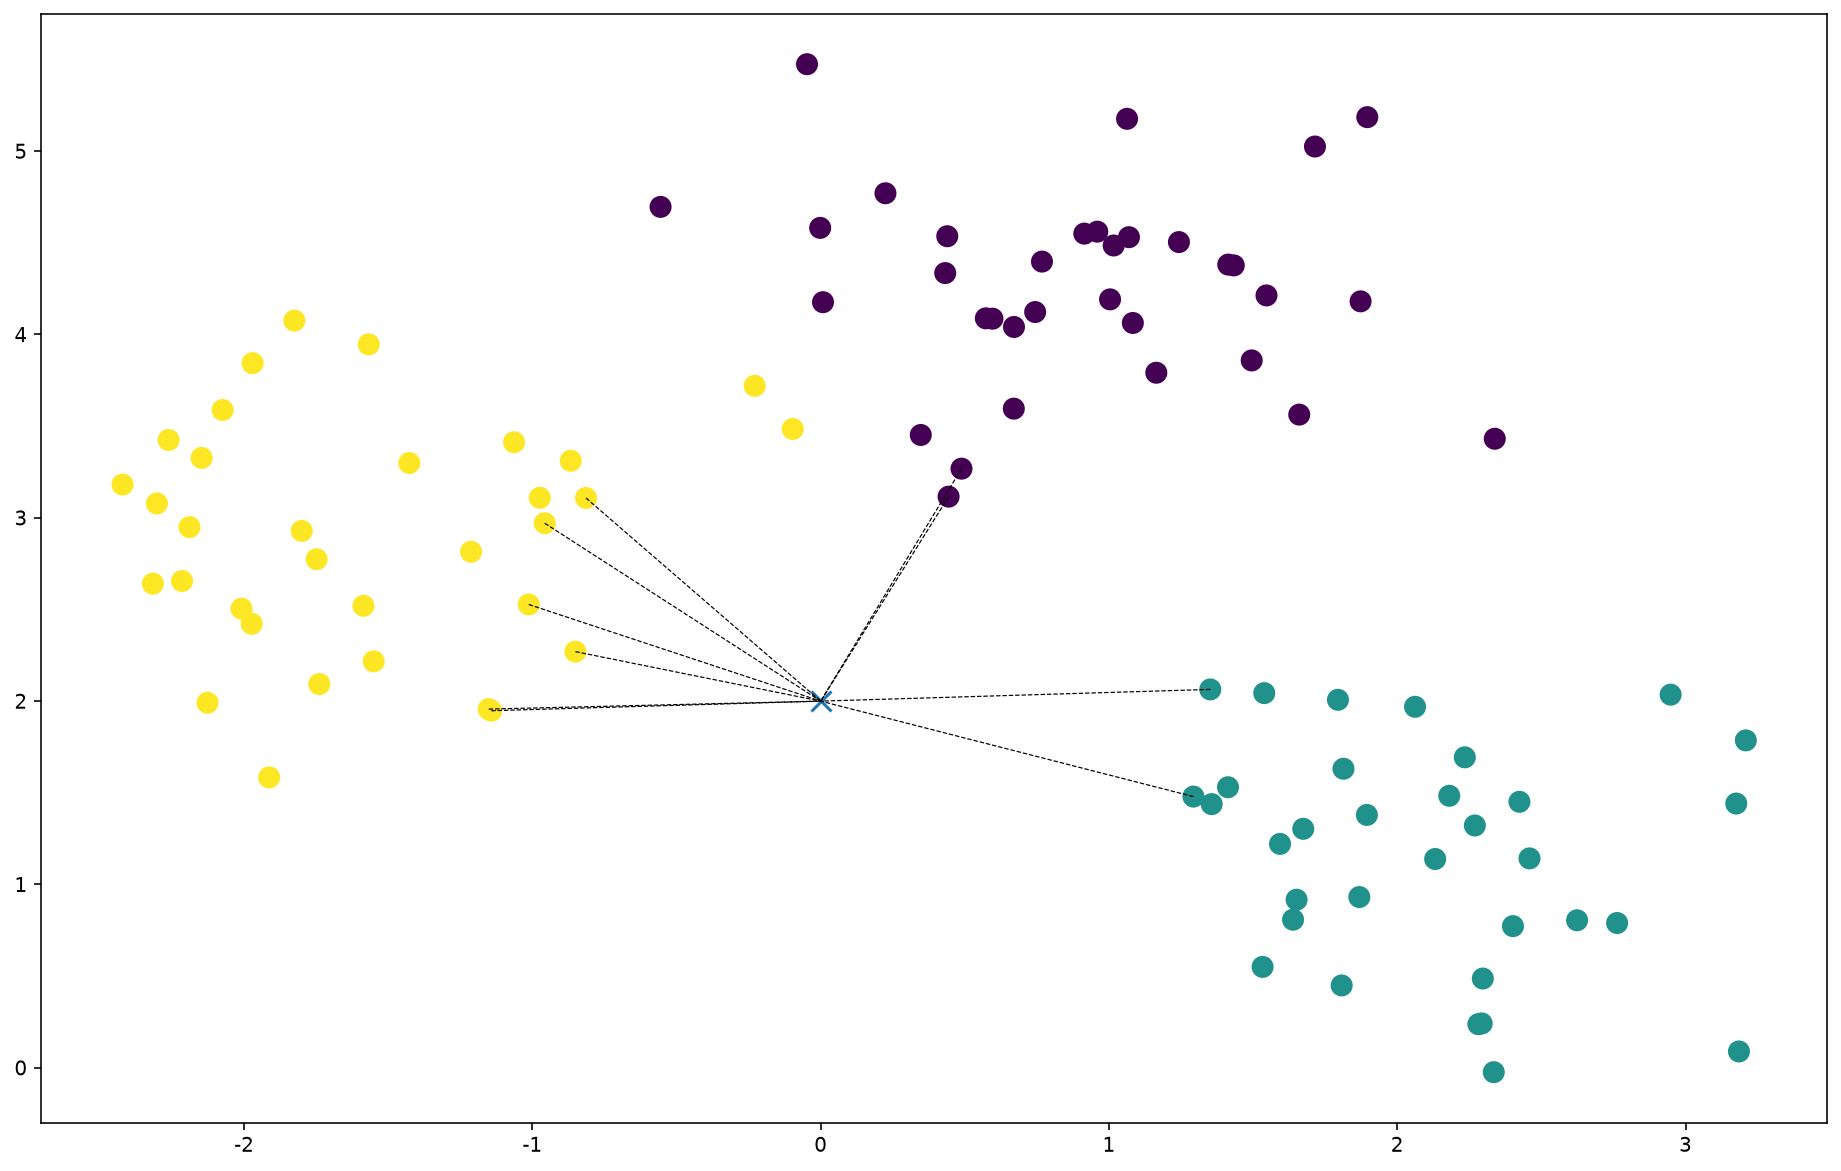

In [7]:
# （5）利用直线表示出与数据点[0,2]距离最近的10个点，根据图形很容易判断出该数据点所属的类别。
plt.figure(figsize=(16, 10), dpi=144)
plt.scatter(X[:, 0], X[:, 1], c=y, s=100)
plt.scatter(X_sample[:, 0], X_sample[:, 1], marker="x", s=100)
for i in neighbors[0]:
    plt.plot([X[i][0], X_sample[0][0]], [X[i][1], X_sample[0][1]], "k--", linewidth=0.6)
plt.show()

&emsp;&emsp;**例5-2-2** 针对鸢尾花数据集，基于KNN算法进行分类，并显示相关分类性能指标。

#### （1）导入库
&emsp;&emsp;从sklearn.datasets 导入 iris数据加载器；从sklearn.model_selection导入train_test_split函数，用以切分训练集和测试集；从sklearn.preprocessing导入StandardScaler类，用以进行数据标准化；从sklearn.neighbors导入KNeighborsClassifier类，用于进行分类操作；从sklearn.metrics导入classification_report函数，用以对预测结果做更加详细的分析。

In [8]:
# （1）导入库
from sklearn.datasets import load_iris
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.utils import Bunch


#### （2）利用load_iris读取鸢尾花数据集
&emsp;&emsp;使用加载器读取数据并且存入变量iris；并设置随机种子random_state=33，设置测试集比例test_size=0.25，使用train_test_split函数分割iris数据集及相应的数据标签集，产生75%的训练样本，25%的测试样本，并将切分后的训练样本返回给X_train变量，测试样本返回给X_test变量，训练标签返回给y_train变量，测试标签返回给y_test变量。

In [9]:
# （2）利用load_iris读取鸢尾花数据集
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.25, random_state=33 # type: ignore
)

#### （3）标准化数据
&emsp;&emsp;语句ss = StandardScaler()，生成标准化实例。  
&emsp;&emsp;语句X_train = ss.fit_transform(X_train)和X_test = ss.transform(X_test)分别对训练集和测试集数据进行标准化，fit_transfrom()函数用于拟合数据，找到数据转换规则，并将数据标准化。transform()是将数据标准化，将测试集按照训练集同样的模型进行转换，得到特征向量。此时可以直接使用之前的fit_transfrom()函数生成的转换规则，若再次使用fit_transform()函数对测试集数据标准化会导致两次标准化后的数据格式不相同。

In [10]:
# （3）标准化数据
ss = StandardScaler()
X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)

#### （4）测试与性能评估
&emsp;&emsp;利用K近邻分类器进行分类；使用fit()函数拟合模型；使用predict()函数预测数据，预测结果储存在变量y_predict中。  
&emsp;&emsp;语句classification_report(y_test,y_predict,target_names=iris.target_names)，比较测试集和训练集的标签数据，计算并展示主要分类指标的文本报告，包括每个分类的精确度、召回率、F1值等信息。分类名使用iris数据集中的标签名。

In [11]:
# （4）使用K近邻分类器对测试数据进行类别预测，预测结果储存在变量y_predict中。
knc = KNeighborsClassifier()
knc.fit(X_train, y_train)
y_predict = knc.predict(X_test)
# 测试与性能评估
print(classification_report(y_test, y_predict, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00         8
  versicolor       0.73      1.00      0.85        11
   virginica       1.00      0.79      0.88        19

    accuracy                           0.89        38
   macro avg       0.91      0.93      0.91        38
weighted avg       0.92      0.89      0.90        38



# SVM支持向量机

例：基于SVM的乳腺癌诊断


In [12]:
# 1、导入包

import sklearn.model_selection as ms
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report
from sklearn.svm import SVC


In [13]:
# 2、准备训练集和测试集，读写并了解样本数据

cancer = load_breast_cancer()
assert isinstance(cancer,Bunch)
X = cancer.data
y = cancer.target
X_train, X_test, y_train, y_test = ms.train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
# 3、构建模型并训练模型

model = SVC(C=1, kernel="rbf")
model.fit(X_train, y_train)
print(model.score(X_train, y_train))

0.9142857142857143


In [15]:
# 4、评估模型预测效果
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.86      0.93        43
           1       0.92      1.00      0.96        71

    accuracy                           0.95       114
   macro avg       0.96      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114

